**Setup**

Import the required libraries and dataset. 

* Dataset: bitext/customer-support-llm-chatbot-training-dataset (Modified)
* Original: https://huggingface.co/datasets/bitext/customer-support-llm-chatbot-training-dataset

MODIFICATIONS (Educational):
- Added synthetic PII columns and injected PII into text
- Introduced data quality issues
- Purpose: Simulate realistic data preprocessing challenges

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Load the chatbot conversation dataset
df = pd.read_csv('./data/customer_support_raw.csv')

# Convert timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Sort by timestamp for time-series analysis
df = df.sort_values('timestamp').reset_index(drop=True)

**Example**

You'll simulate a production monitoring system that tracks your chatbot's health minute-by-minute. The dataset contains conversations with timestamps, allowing you to detect when sudden incidents occur.

Key columns for incident detection:
- **Time**: `timestamp`
- **Health metrics**: `error_occurred`, `latency_seconds`, `hallucinated`, `resolved`
- **Model info**: `model_used`, `model_tier`

Let's see the data structure:

In [2]:
print("=== Production Monitoring Dataset ===")
print(f"Total conversations: {len(df):,}")
print(f"Time range: {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"Duration: {(df['timestamp'].max() - df['timestamp'].min()).days} days")
print(f"\nModels in use:")
print(df['model_used'].value_counts())
print(f"\nOverall health:")
print(f"  Error rate: {df['error_occurred'].mean():.1%}")
print(f"  Avg latency: {df['latency_seconds'].mean():.2f}s")
print(f"  Hallucination rate: {df['hallucinated'].mean():.1%}")
print(f"Columns: {df.columns.tolist()}")

=== Production Monitoring Dataset ===
Total conversations: 26,872
Time range: 2025-01-01 00:00:39 to 2025-01-30 23:59:43
Duration: 29 days

Models in use:
model_used
gpt-4-turbo      12950
gpt-4            12765
gpt-3.5-turbo     1154
rule-based           3
Name: count, dtype: int64

Overall health:
  Error rate: 0.3%
  Avg latency: 2.11s
  Hallucination rate: 8.2%
Columns: ['conversation_id', 'customer_id', 'customer_name', 'email', 'phone', 'customer_type', 'zipcode', 'timestamp', 'flags', 'instruction_raw', 'response_raw', 'category', 'intent', 'model_tier', 'model_used', 'tokens_used', 'cost', 'latency_seconds', 'conversation_turns', 'resolved', 'escalated_to_human', 'csat_score', 'hallucinated', 'error_occurred']


Before you can detect problems, you need to organize your data by time and calculate health scores for each hour.

1. Create a new column called `hour` that rounds each conversation's timestamp down to the nearest hour
2. Group all conversations by this `hour` column
3. For each hour, calculate:
    - Error rate: The average (mean) of the `error_occurred` column (this gives you a percentage)
    - Average latency: The average (mean) of the `latency_seconds` column
    - Hallucination rate: The average (mean) of the `hallucinated` column
    - Resolution rate: The average (mean) of the `resolved` column
    - Conversation count: How many conversations happened that hour
4. Save all these calculations in a new dataframe called `hourly_health`

In [7]:
# Create hourly time windows
df['hour'] = df['timestamp'].dt.floor('h')

# Calculate hourly health metrics
hourly_health = df.groupby('hour').agg({
    'error_occurred': 'mean',
    'latency_seconds': 'mean',
    'hallucinated': 'mean',
    'resolved': 'mean',
    'conversation_id': 'count'
}).rename(columns={
    'error_occurred': 'error_rate',
    'latency_seconds': 'avg_latency',
    'hallucinated': 'hallucination_rate',
    'resolved': 'resolution_rate',
    'conversation_id': 'conversations'
})

# Display the results
print("=== Hourly Health Metrics ===")
print(f"\nTotal hours monitored: {len(hourly_health)}")
print(f"\nFirst 10 hours of data:")
print(hourly_health.head(10))

print(f"\nSummary statistics:")
print(f"  Average error rate: {hourly_health['error_rate'].mean():.1%}")
print(f"  Average latency: {hourly_health['avg_latency'].mean():.2f}s")
print(f"  Average hallucination rate: {hourly_health['hallucination_rate'].mean():.1%}")
print(f"  Average resolution rate: {hourly_health['resolution_rate'].mean():.1%}")

=== Hourly Health Metrics ===

Total hours monitored: 720

First 10 hours of data:
                     error_rate  avg_latency  hallucination_rate  \
hour                                                               
2025-01-01 00:00:00         0.0     2.121628            0.139535   
2025-01-01 01:00:00         0.0     2.055000            0.117647   
2025-01-01 02:00:00         0.0     2.000385            0.076923   
2025-01-01 03:00:00         0.0     2.086222            0.066667   
2025-01-01 04:00:00         0.0     2.024375            0.062500   
2025-01-01 05:00:00         0.0     2.049091            0.030303   
2025-01-01 06:00:00         0.0     2.125750            0.075000   
2025-01-01 07:00:00         0.0     1.972326            0.093023   
2025-01-01 08:00:00         0.0     2.004167            0.083333   
2025-01-01 09:00:00         0.0     2.241364            0.022727   

                     resolution_rate  conversations  
hour                                          

Now that you have hourly metrics, you need to determine which hours are "healthy" and which are "unhealthy" based on warning levels.

1. Define your threshold limits at the top of your code:
    - `ERROR_THRESHOLD = 0.10` (10%)
    - `LATENCY_THRESHOLD = 5.0` (5 seconds)
    - `HALLUCINATION_THRESHOLD = 0.10` (10%)
    - `CONSECUTIVE_FAILURES = 3` (need 3 in a row to call it an incident)
2. Create new columns in hourly_health that check if each metric is healthy:
    - `error_healthy`: Is the error rate at or below the threshold?
    - `latency_healthy`: Is the latency at or below the threshold?
    - `hallucination_healthy`: Is the hallucination rate at or below the threshold?
    - `overall_healthy`: Are ALL three metrics healthy?
3. Print out a few examples showing hours and whether they passed or failed each health check


In [8]:
# Define health thresholds
ERROR_THRESHOLD = 0.10
LATENCY_THRESHOLD = 5.0
HALLUCINATION_THRESHOLD = 0.10
CONSECUTIVE_FAILURES = 3

# Check if each metric is healthy
hourly_health['error_healthy'] = hourly_health['error_rate'] <= ERROR_THRESHOLD
hourly_health['latency_healthy'] = hourly_health['avg_latency'] <= LATENCY_THRESHOLD
hourly_health['hallucination_healthy'] = hourly_health['hallucination_rate'] <= HALLUCINATION_THRESHOLD
hourly_health['overall_healthy'] = hourly_health['error_healthy'] & hourly_health['latency_healthy'] & hourly_health['hallucination_healthy']

# Display results
print("=== Health Check Thresholds ===")
print(f"\nHealth thresholds:")
print(f"  • Error rate: ≤{ERROR_THRESHOLD:.0%}")
print(f"  • Latency: ≤{LATENCY_THRESHOLD:.1f}s")
print(f"  • Hallucination rate: ≤{HALLUCINATION_THRESHOLD:.0%}")

print(f"\n{'='*80}")
print("Sample of Health Checks (First 10 Hours):")
print(f"{'='*80}")
print(hourly_health[['error_rate', 'error_healthy', 'avg_latency', 'latency_healthy', 
                      'hallucination_rate', 'hallucination_healthy', 'overall_healthy']].head(10))

# Summary statistics
total_hours = len(hourly_health)
healthy_hours = hourly_health['overall_healthy'].sum()
unhealthy_hours = total_hours - healthy_hours

print(f"\n{'='*80}")
print("Overall Health Summary:")
print(f"{'='*80}")
print(f"  Total hours: {total_hours}")
print(f"  Healthy hours: {healthy_hours} ({(healthy_hours/total_hours)*100:.1f}%)")
print(f"  Unhealthy hours: {unhealthy_hours} ({(unhealthy_hours/total_hours)*100:.1f}%)")

print(f"\nBreakdown of failures:")
print(f"  • Error rate failures: {(~hourly_health['error_healthy']).sum()} hours")
print(f"  • Latency failures: {(~hourly_health['latency_healthy']).sum()} hours")
print(f"  • Hallucination failures: {(~hourly_health['hallucination_healthy']).sum()} hours")

=== Health Check Thresholds ===

Health thresholds:
  • Error rate: ≤10%
  • Latency: ≤5.0s
  • Hallucination rate: ≤10%

Sample of Health Checks (First 10 Hours):
                     error_rate  error_healthy  avg_latency  latency_healthy  \
hour                                                                           
2025-01-01 00:00:00         0.0           True     2.121628             True   
2025-01-01 01:00:00         0.0           True     2.055000             True   
2025-01-01 02:00:00         0.0           True     2.000385             True   
2025-01-01 03:00:00         0.0           True     2.086222             True   
2025-01-01 04:00:00         0.0           True     2.024375             True   
2025-01-01 05:00:00         0.0           True     2.049091             True   
2025-01-01 06:00:00         0.0           True     2.125750             True   
2025-01-01 07:00:00         0.0           True     1.972326             True   
2025-01-01 08:00:00         0.0     

Now find the real incidents (3+ consecutive unhealthy hours) and make charts to visualize what happened.

1. Update the function, `detect_consecutive_failures()`, that finds when a metric stays unhealthy for at least `threshold` hours in a row
2. Use this function to find incidents for each metric and save as `error_incidents`, `latency_incidents`, and `hallucination_incidents`
3. Combine all incidents into one list `all_incidents` (removing duplicates)
4. Print a summary report showing:
    - Total number of incidents found
    - How many incidents for each type
5. Create three line charts (stacked vertically) showing:
    - Chart 1: Error rate over time with the threshold as a red dashed line
    - Chart 2: Latency over time with the threshold as a red dashed line
    - Chart 3: Hallucination rate over time with the threshold as a red dashed line
    - Shade incident periods in red on each chart

=== Incident Detection Results ===

Monitoring period: 720 hours
Incident trigger: 3 consecutive unhealthy hours

INCIDENT SUMMARY:

Total incidents detected: 18

Incidents by metric:
  • Error rate incidents: 0
  • Latency incidents: 0
  • Hallucination incidents: 18


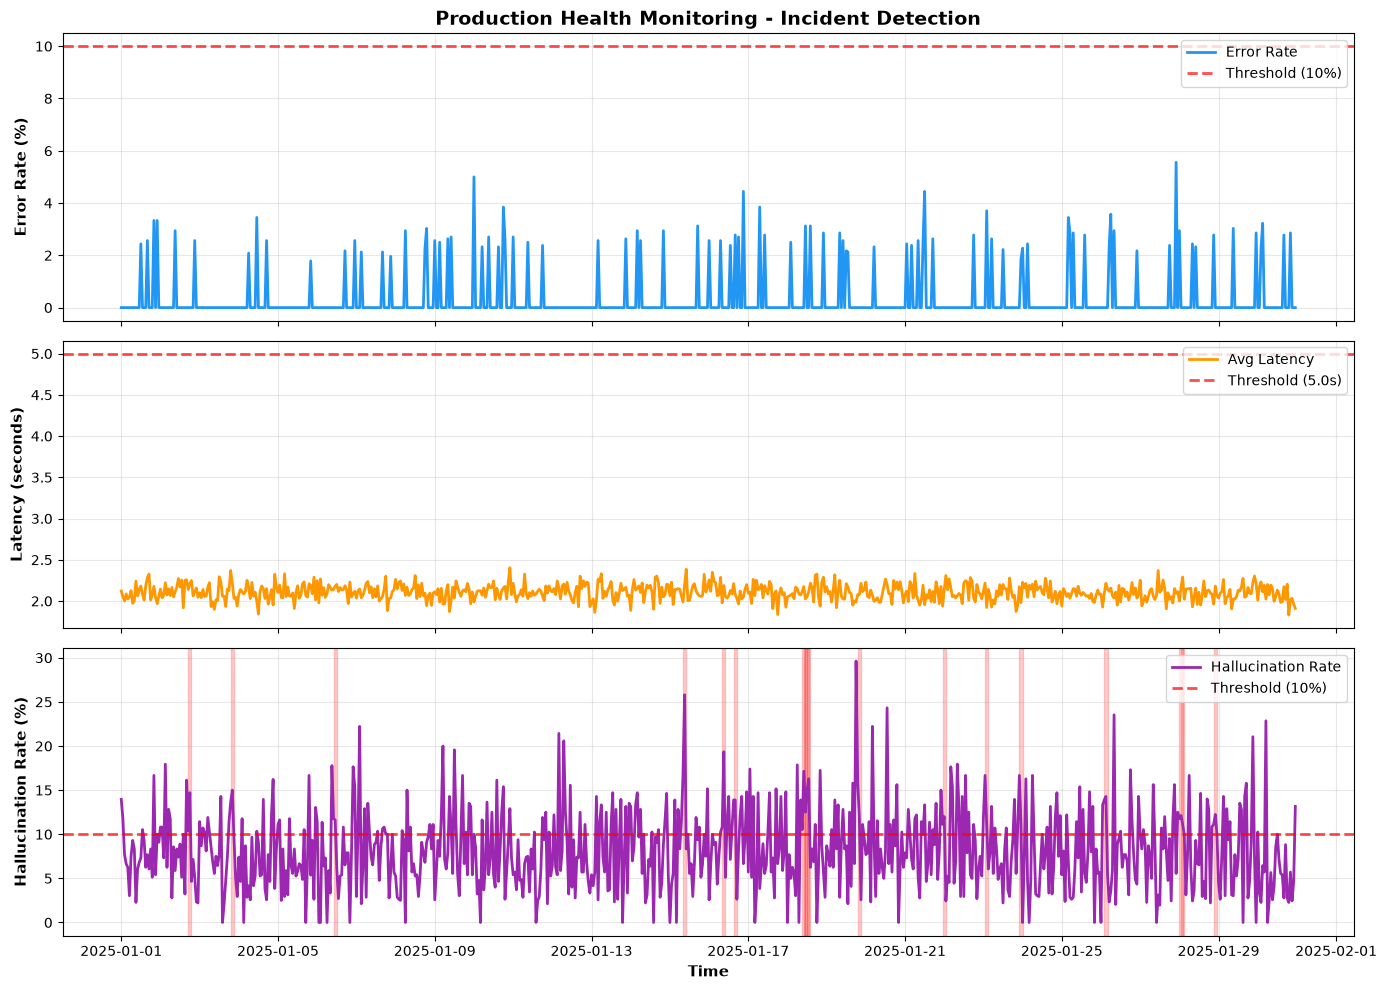

In [9]:
# Function to detect consecutive failures
def detect_consecutive_failures(series, threshold):
    """Detect when series has >= threshold consecutive False values."""
    incidents = []
    consecutive_count = 0
    
    for idx, value in series.items():
        if not value:  # Unhealthy
            consecutive_count += 1
            if consecutive_count >= threshold:
                incidents.append(idx)
        else:  # Healthy
            consecutive_count = 0
    
    return incidents

# Find incidents for each metric
error_incidents = detect_consecutive_failures(hourly_health['error_healthy'], CONSECUTIVE_FAILURES)
latency_incidents = detect_consecutive_failures(hourly_health['latency_healthy'], CONSECUTIVE_FAILURES)
hallucination_incidents = detect_consecutive_failures(hourly_health['hallucination_healthy'], CONSECUTIVE_FAILURES)

# Combine all incidents
all_incidents = set(error_incidents + latency_incidents + hallucination_incidents)

# Print incident report
print("=== Incident Detection Results ===")
print(f"\nMonitoring period: {len(hourly_health)} hours")
print(f"Incident trigger: {CONSECUTIVE_FAILURES} consecutive unhealthy hours")

print(f"\n{'='*80}")
print("INCIDENT SUMMARY:")
print(f"{'='*80}")

print(f"\nTotal incidents detected: {len(all_incidents)}")
print(f"\nIncidents by metric:")
print(f"  • Error rate incidents: {len(error_incidents)}")
print(f"  • Latency incidents: {len(latency_incidents)}")
print(f"  • Hallucination incidents: {len(hallucination_incidents)}")

# Create visualizations

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

hours = hourly_health.index

# Plot 1: Error Rate
axes[0].plot(hours, hourly_health['error_rate'] * 100, color='#2196F3', linewidth=2, label='Error Rate')
axes[0].axhline(y=ERROR_THRESHOLD * 100, color='red', linestyle='--', linewidth=2, 
                label=f'Threshold ({ERROR_THRESHOLD:.0%})', alpha=0.7)
for incident in error_incidents:
    axes[0].axvspan(incident - timedelta(hours=1), incident + timedelta(hours=1), 
                    alpha=0.2, color='red')
axes[0].set_ylabel('Error Rate (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Production Health Monitoring - Incident Detection', fontsize=14, fontweight='bold')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

# Plot 2: Latency
axes[1].plot(hours, hourly_health['avg_latency'], color='#FF9800', linewidth=2, label='Avg Latency')
axes[1].axhline(y=LATENCY_THRESHOLD, color='red', linestyle='--', linewidth=2, 
                label=f'Threshold ({LATENCY_THRESHOLD:.1f}s)', alpha=0.7)
for incident in latency_incidents:
    axes[1].axvspan(incident - timedelta(hours=1), incident + timedelta(hours=1), 
                    alpha=0.2, color='red')
axes[1].set_ylabel('Latency (seconds)', fontsize=11, fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

# Plot 3: Hallucination Rate
axes[2].plot(hours, hourly_health['hallucination_rate'] * 100, color='#9C27B0', linewidth=2, 
             label='Hallucination Rate')
axes[2].axhline(y=HALLUCINATION_THRESHOLD * 100, color='red', linestyle='--', linewidth=2, 
                label=f'Threshold ({HALLUCINATION_THRESHOLD:.0%})', alpha=0.7)
for incident in hallucination_incidents:
    axes[2].axvspan(incident - timedelta(hours=1), incident + timedelta(hours=1), 
                    alpha=0.2, color='red')
axes[2].set_ylabel('Hallucination Rate (%)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Time', fontsize=11, fontweight='bold')
axes[2].legend(loc='upper right')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


With your visualization, you can immediately identify unhealthy intervals and incidents, all due to high hallucination rates!